In [5]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation"
# !pip install -q lightning torchmetrics formulaic interface_meta statsmodels
# !pip install -q -e . --no-deps

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation


In [6]:
import torch 
import numpy as np
from pathlib import Path 
import pandas as pd 
from tqdm import tqdm 
import time
import math 
import copy
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Data

In [7]:
RV_PATH = 'data/SP500_RV_5min.xlsx'

LAGS = 5
N_SAMPLES = 200

STANDARDIZE = False 
LOG = True
N_TRAIN = 2000

raw = pd.read_excel(RV_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
dates = raw['Date'].to_numpy()
rv = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)

if LOG: 
    y = torch.log(rv)
else:
    y = rv.clone()

def define_features(rv, n_train=2000, lags=5, h=1):
    T = rv.shape[0]
    ts = torch.arange(lags + h - 1, T)                       # valid target times
    X = torch.stack([rv[t-h-lags+1 : t-h+1, 0] for t in ts.tolist()])   # (n, lags), oldest -> newest
    Y = rv[ts]                                               # (n, 1)
    assert torch.equal(X[:, -1], rv[ts - h, 0])              # newest lag is exactly y_{t-h}
    tr = ts < n_train
    return (X[tr], Y[tr]), (X[~tr], Y[~tr])                  # test always has T - n_train rows

(x_train, y_train), (x_test, y_test) = define_features(y, n_train = 2000, lags  = 5,)

In [ ]:
class LogStandardizer:
    def fit(self, rv_train):
        y = torch.log(rv_train); self.mu, self.sd = y.mean(), y.std(); return self
    def transform(self, rv): return (torch.log(rv) - self.mu) / self.sd
    def inverse(self, z):    return torch.exp(z * self.sd + self.mu)

# Model Configuration 

In [8]:
from rcdiff import BaseScheduler, DDPM  
from rcdiff.models import SimpleMLP 

scheduler = BaseScheduler(K = 100, 
                          beta_1 = 1e-4,
                          beta_K = 0.1,
                          mode = 'linear')

ddpm = DDPM(scheduler=scheduler)

denoiser = SimpleMLP(in_dim = 1, 
                     cond_dim = 5, 
                     dim_hids=[64, 124, 64],
                     time_dim=128)

# TRAIN

In [9]:
def train_ddpm(denoiser, ddpm, x_train, y_train, *, max_iters=20_000, batch_size=128,
               lr=1e-3, grad_clip=1.0, val_fraction=0.15, n_rep=8, eval_every=100,
               patience=20, seed=12345):
    dev = next(denoiser.parameters()).device
    x_train, y_train = x_train.to(dev), y_train.to(dev)
    K = ddpm.scheduler.K
    n_val = int(val_fraction * len(y_train)); n_tr = len(y_train) - n_val   # chronological split
    x_tr, y_tr, x_va, y_va = x_train[:n_tr], y_train[:n_tr], x_train[n_tr:], y_train[n_tr:]

    g_cpu   = torch.Generator().manual_seed(seed)                    # indices and k
    g_noise = torch.Generator(device=dev).manual_seed(seed + 1)      # training noise
    g_val   = torch.Generator(device=dev).manual_seed(seed + 2)      # validation noise

    # fixed validation set: n_rep different (k, eps) per validation point
    x_va_r, y_va_r = x_va.repeat(n_rep, 1), y_va.repeat(n_rep, 1)
    k_va = torch.randint(0, K, (len(y_va_r),), generator=torch.Generator().manual_seed(seed + 3)).to(dev)
    y_va_noisy, eps_va = ddpm.q_sample(y_va_r, k=k_va, generator=g_val)

    opt = torch.optim.Adam(denoiser.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=max(1, patience // 3), min_lr=1e-6)
    best_val, best_state, bad = float("inf"), None, 0
    run, n_run, hist = torch.zeros((), device=dev), 0, []

    for it in tqdm(range(1, max_iters + 1), desc="Training", leave=False):
        denoiser.train()
        idx = torch.randint(0, n_tr, (batch_size,), generator=g_cpu).to(dev)
        k   = torch.randint(0, K,    (batch_size,), generator=g_cpu).to(dev)
        y_noisy, eps = ddpm.q_sample(y_tr[idx], k=k, generator=g_noise)
        loss = F.mse_loss(denoiser(y_noisy, k=k, s=x_tr[idx]), eps)
        opt.zero_grad(set_to_none=True); loss.backward()
        if grad_clip: torch.nn.utils.clip_grad_norm_(denoiser.parameters(), float(grad_clip))
        opt.step()
        run += loss.detach(); n_run += 1

        if it % eval_every == 0:
            denoiser.eval()
            with torch.no_grad():
                val = F.mse_loss(denoiser(y_va_noisy, k=k_va, s=x_va_r), eps_va).item()
            train = (run / n_run).item(); run.zero_(); n_run = 0
            if not math.isfinite(val): raise RuntimeError(f"Non-finite val loss at it {it}")
            sched.step(val)
            if val < best_val: best_val, bad, best_state = val, 0, copy.deepcopy(denoiser.state_dict())
            else: bad += 1
            hist.append((it, train, val))
            if bad >= patience: break

    if best_state is not None: denoiser.load_state_dict(best_state)
    denoiser.eval()
    return pd.DataFrame(hist, columns=["iter", "train", "val"])

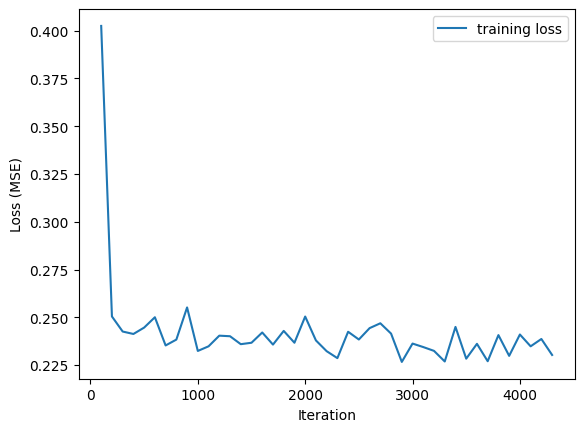

In [10]:
loss = train_ddpm(denoiser, ddpm, x_train, y_train, max_iters=20_000, batch_size=128,
               lr=1e-3, grad_clip=1.0, val_fraction=0.15, n_rep=8, eval_every=100,
               patience=20, seed=12345)


plt.plot(loss['iter'], loss['train'], label = 'training loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Iteration')
plt.legend()
plt.show()

# Test

In [13]:
@torch.no_grad()
def sample_predictive(ddpm : DDPM, denoiser, X, n_samples=200, chunk_size=64, generator=None, desc="Sampling"):
    """X: (L, lags) aligned conditioning rows -> draws of shape (L, n_samples, N)."""
    denoiser.eval()
    y_like = X.new_zeros(1, 1)                               # reverse_process only reads shape[-1] = N
    out = []
    for i in tqdm(range(0, len(X), chunk_size), desc=desc):
        s = X[i:i + chunk_size].repeat_interleave(n_samples, dim=0)      # (c*n_samples, lags)
        y_hat, _ = ddpm.reverse_process(x=y_like, s=s, denoiser=denoiser,
                                        n_samples=s.shape[0],
                                        )
        out.append(y_hat.view(-1, n_samples, y_hat.shape[-1]))
    return torch.cat(out)

# In-Sample Check

In [ ]:
def in_sample_check(ddpm, denoiser, x_train, **kw):
    return sample_predictive(ddpm, denoiser, x_train, desc="In-sample check", **kw)


in_sample_pred = in_sample_check(ddpm, denoiser, x_train, n_samples=N_SAMPLES)

In-sample check: 100%|██████████| 32/32 [05:55<00:00, 11.10s/it]


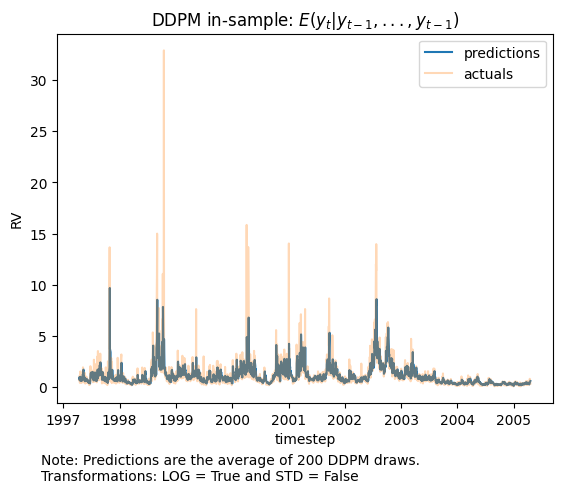

In [ ]:
if LOG:
    actuals = torch.exp(y_train.flatten()).clone().detach().numpy()
    pred = torch.mean(torch.exp(in_sample_pred), dim = 1).flatten().detach().numpy()
else:
    actuals = y_train.flatten().clone().detach().numpy()
    pred = torch.mean(in_sample_pred, dim = 1).flatten().detach().numpy()

pred_df = pd.DataFrame({'dates' : dates[LAGS:N_TRAIN],
                        'predictions' : pred,
                        'actuals' : actuals})

plt.plot(pred_df['dates'], pred_df['predictions'], label = 'predictions')
plt.plot(pred_df['dates'], pred_df['actuals'], label = 'actuals', alpha = 0.3)
plt.title(r'DDPM in-sample: $E(y_t|y_{t-1}, ...,y_{t-1})$')
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.figtext(0.1, -0.05, f"Note: Predictions are the average of {N_SAMPLES} DDPM draws. \nTransformations: LOG = {LOG} and STD = {STANDARDIZE}", ha="left", fontsize=10,)
plt.show()


# Out-Of-Sample

In [11]:
@torch.no_grad()
def conditional_distribution(ddpm : DDPM,
                             denoiser,
                             y_test : torch.Tensor,
                             x_test : torch.Tensor,
                             n_samples : int = 1, 
                            ): 
  
    x_test = x_test.expand(n_samples, -1)   
    x_hat, full_reverse = ddpm.reverse_process(x=y_test, s=x_test, denoiser=denoiser, n_samples=n_samples)
    return x_hat, full_reverse

x_hat, full_reverse = conditional_distribution(ddpm,
                         denoiser,
                         y_test = y_test[0],
                         x_test = x_test[0],
                         n_samples = 1
                        )

In [14]:
@torch.no_grad()
def one_step_ahead_forecast(ddpm, denoiser, x_test, **kw):
    return sample_predictive(ddpm, denoiser, x_test, desc="Out-of-sample", **kw)

forecast = one_step_ahead_forecast(ddpm, denoiser, x_test, n_samples=200)

Out-of-sample: 100%|██████████| 33/33 [10:11<00:00, 18.54s/it]


In [18]:
def qlike(actual, pred):
    r = actual/pred
    return np.mean(r-np.log(r)-1)

def mse(actual, pred):
    return np.mean((actual-pred)**2)

def mae(actual, pred):
    return np.mean(np.abs(actual-pred))


if LOG:
    actuals = torch.exp(y_test.flatten()).clone().detach().numpy()
    pred = torch.mean(torch.exp(forecast), dim = 1).flatten().detach().numpy()
else:
    actuals = y_test.flatten().clone().detach().numpy()
    pred = torch.mean(forecast, dim = 1).flatten().detach().numpy()

pred_df = pd.DataFrame({'dates' : dates[N_TRAIN:],
                        'predictions' : pred,
                        'actuals' : actuals})


mse_test = mse(actuals, pred)
mae_test = mae(actuals, pred)
qlike_test = qlike(actuals, pred)

print('MSE of the test:', mse_test)
print('MAE of the test:', mae_test)
print('QLIKE of the test:', qlike_test)

MSE of the test: 3.8827662
MAE of the test: 0.4989582
QLIKE of the test: 0.14626135


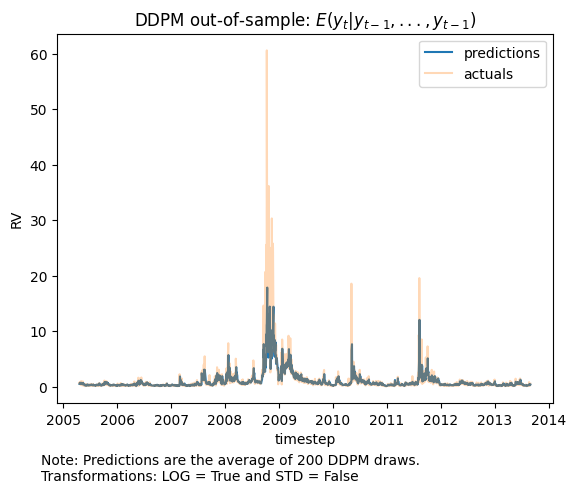

In [19]:
plt.plot(pred_df['dates'], pred_df['predictions'], label = 'predictions')
plt.plot(pred_df['dates'], pred_df['actuals'], label = 'actuals', alpha = 0.3)
plt.title(r'DDPM out-of-sample: $E(y_t|y_{t-1}, ...,y_{t-1})$')
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.figtext(0.1, -0.05, f"Note: Predictions are the average of {N_SAMPLES} DDPM draws. \nTransformations: LOG = {LOG} and STD = {STANDARDIZE}", ha="left", fontsize=10,)
plt.show()